# Проверка дизайна и данных эксперимента

Цель работы — проверить соотношение групп, баланс активности до эксперимента
и частоту ошибок. Только если эти проверки пройдены, можно перейти
к проверке значимости различий конверсии.

Плановое соотношение групп — **50/50**, уровень значимости — **0,05**.
Единица наблюдения и рандомизации — пользователь.
Данные искусственные, персональных данных в них нет.

Ноутбук запускается сверху вниз. Если `experiment_data.csv` лежит рядом,
используется именно этот файл. Результаты запуска уже сохранены в ноутбуке.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
from scipy.stats import chisquare, mannwhitneyu, fisher_exact

ALPHA = 0.05
GROUPS = ['control', 'test']
MY_SEED = 648345

## 1. Генерация данных

Seed был выбран один раз командой из задания:
`MY_SEED = np.random.randint(5000000, size=1)[0]`.
Получилось **648345**, число пользователей — **4907**.
Параметры генератора не менялись, повторный seed не подбирался.

Исправлена синтаксическая опечатка в условии: создание `DataFrame`
нужно закрыть символами `})`, а не `}]`.

Ниже сохранён исходный алгоритм с уже выбранным seed. При наличии CSV
генерация пропускается. Если CSV отсутствует, код позволяет воспроизвести
тот же набор данных, не выбирая новый seed.

In [2]:
data_path = Path('experiment_data.csv')

if data_path.exists():
    print('experiment_data.csv уже существует. Повторная генерация не выполняется.')
else:
    np.random.seed(MY_SEED)
    n_users = np.random.randint(1000, 10000, size=1)[0]

    pre_activity = np.random.exponential(scale=10, size=n_users).astype(int)

    # Эта строка оставлена, как в условии, хотя её результат затем заменяется.
    variant = np.random.choice(
        ['control', 'test'], size=n_users, p=[0.4, 0.6]
    )
    prob_test = 0.4 + 0.3 * (pre_activity / pre_activity.max())
    variant2 = np.where(
        np.random.random(n_users) < prob_test, 'test', 'control'
    )
    variant = variant2

    error_flag = np.zeros(n_users)
    error_flag[variant == 'control'] = np.random.binomial(
        1, 0.01, sum(variant == 'control')
    )
    error_flag[variant == 'test'] = np.random.binomial(
        1, 0.02, sum(variant == 'test')
    )

    conversion_prob = 0.05 + 0.01 * (pre_activity / pre_activity.max())
    converted = np.random.binomial(1, conversion_prob, n_users)

    start_date = pd.Timestamp('2026-05-01')
    dates = [
        start_date + pd.Timedelta(days=np.random.randint(0, 14))
        for _ in range(n_users)
    ]

    generated_data = pd.DataFrame({
        'user_id': range(n_users),
        'variant': variant,
        'converted': converted,
        'error_flag': error_flag,
        'pre_activity': pre_activity,
        'date': dates
    })
    generated_data.to_csv(data_path, index=False)
    print(f'Сохранено {n_users} строк, seed = {MY_SEED}.')

experiment_data.csv уже существует. Повторная генерация не выполняется.


## 2. Загрузка и базовая проверка

Проверю пропуски, повторяющиеся `user_id`, названия групп и допустимые
значения признаков. В этом задании каждый пользователь должен встречаться
один раз. Нули и единицы в `error_flag` записаны как `0.0` и `1.0` —
это допустимые значения бинарного признака.

In [3]:
# Скрипт читает CSV из текущей папки.
df = pd.read_csv('experiment_data.csv', parse_dates=['date'])

print('Размер данных:', df.shape)
print(df.head().to_string(index=False))
print('\nПропуски по столбцам:')
print(df.isna().sum().to_string())
print('\nПовторяющихся user_id:', df['user_id'].duplicated().sum())

assert not df.isna().any().any(), 'В данных есть пропуски'
assert df['user_id'].is_unique, 'Есть повторяющиеся пользователи'
assert set(df['variant'].unique()) == set(GROUPS), 'Неверные группы'
assert df['converted'].isin([0, 1]).all(), 'Неверные значения converted'
assert df['error_flag'].isin([0, 1]).all(), 'Неверные значения error_flag'
assert (df['pre_activity'] >= 0).all(), 'Отрицательная активность'

print('\nБазовые проверки пройдены.')
print('Даты:', df['date'].min().date(), '—', df['date'].max().date())

Размер данных: (4907, 6)
 user_id variant  converted  error_flag  pre_activity       date
       0 control          0         0.0             4 2026-05-01
       1 control          0         0.0            28 2026-05-09
       2    test          0         0.0             0 2026-05-02
       3 control          0         0.0            12 2026-05-11
       4    test          0         0.0            15 2026-05-05

Пропуски по столбцам:
user_id         0
variant         0
converted       0
error_flag      0
pre_activity    0
date            0

Повторяющихся user_id: 0

Базовые проверки пройдены.
Даты: 2026-05-01 — 2026-05-14


В данных 4907 строк и 6 столбцов, пропусков и повторяющихся пользователей нет.
Даты лежат в диапазоне 1–14 мая 2026 года. Отдельный анализ временных
трендов не выполняю: по условию он необязателен.

In [4]:
# Среднее бинарного признака равно доле единиц.
summary = df.groupby('variant').agg(
    users=('user_id', 'size'),
    conversions=('converted', 'sum'),
    conversion_rate=('converted', 'mean'),
    errors=('error_flag', 'sum'),
    error_rate=('error_flag', 'mean'),
    activity_mean=('pre_activity', 'mean'),
    activity_median=('pre_activity', 'median')
).reindex(GROUPS)

summary['errors'] = summary['errors'].astype(int)
summary['group_pct'] = 100 * summary['users'] / len(df)
summary['conversion_pct'] = 100 * summary['conversion_rate']
summary['error_pct'] = 100 * summary['error_rate']

print(summary[[
    'users', 'group_pct', 'conversions', 'conversion_pct',
    'errors', 'error_pct', 'activity_mean', 'activity_median'
]].round(3).to_string())

control = df[df['variant'] == 'control']
test = df[df['variant'] == 'test']
warnings = []

         users  group_pct  conversions  conversion_pct  errors  error_pct  activity_mean  activity_median
variant                                                                                                  
control   2789     56.837          152           5.450      27      0.968          8.798              6.0
test      2118     43.163          119           5.619      49      2.314         10.283              7.0


| Показатель | control | test |
|---|---:|---:|
| Пользователей | 2789 | 2118 |
| Доля группы | 56,84% | 43,16% |
| Конверсий | 152 | 119 |
| Конверсия | 5,450% | 5,619% |
| Ошибок | 27 | 49 |
| Частота ошибок | 0,968% | 2,314% |
| Средняя активность до эксперимента | 8,798 | 10,283 |
| Медианная активность | 6 | 7 |

Конверсия в тесте численно выше, но сначала нужно проверить дизайн.

## 3. Проверка SRM

**H₀:** распределение пользователей соответствует плану 50/50.
**H₁:** соотношение отличается от 50/50.

Использую критерий хи-квадрат Пирсона. Ожидаемая численность каждой
группы — `len(df) / 2`. При нечётном числе участников это дробное число,
округлять его не нужно. Все ожидаемые частоты значительно больше 5.

In [5]:
observed = [len(control), len(test)]
expected = [len(df) / 2, len(df) / 2]
chi2_stat, p_srm = chisquare(observed, f_exp=expected)

print('Наблюдаемые численности:', observed)
print('Ожидаемые численности:', expected)
print(f'Хи-квадрат = {chi2_stat:.3f}; p-value = {p_srm:.6g}')

if p_srm < ALPHA:
    warnings.append('SRM обнаружен')
    print('SRM обнаружен')
else:
    print('Статистически значимый SRM не обнаружен')

Наблюдаемые численности: [2789, 2118]
Ожидаемые численности: [2453.5, 2453.5]
Хи-квадрат = 91.755; p-value = 9.8108e-22
SRM обнаружен


**Результат:** χ² = 91,755; p-value ≈ **9,81 × 10⁻²²** < 0,05.
Соотношение 2789/2118 не соответствует ожидаемому 50/50. SRM обнаружен.

В исходном коде первое назначение с вероятностями 0,4/0,6 перезаписывается
строкой `variant = variant2`. Поэтому итоговое соотношение нельзя описывать
как «40% control и 60% test». Оно задаётся формулой `prob_test`,
а фактические доли необходимо посчитать по CSV.

## 4. Баланс pre_activity

В комментарии генератора написано «логнормальное распределение»,
но фактически вызывается `np.random.exponential`, после чего значения
приводятся к целым числам. Получается не непрерывная логнормальная,
а целочисленная ковариата на основе экспоненциального распределения.

Посмотрю на её форму и сравню группы U-критерием Манна — Уитни.
**H₀:** распределения ковариаты в группах одинаковы.
**H₁:** группы различаются по ковариате.
Это не непосредственный тест равенства средних или медиан.

Асимметрия pre_activity: 1.997


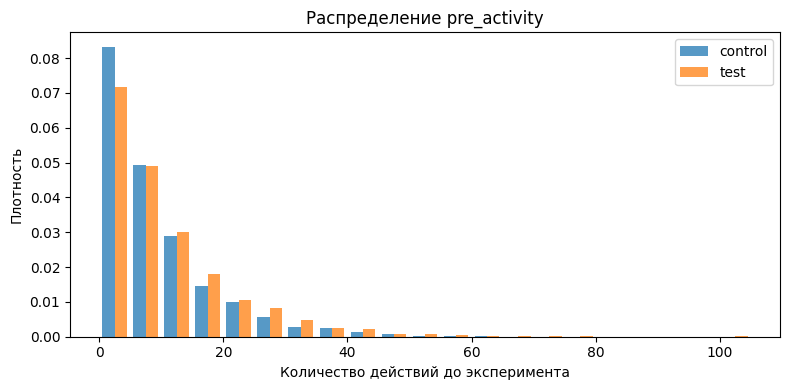

In [6]:
import matplotlib.pyplot as plt

bins = np.arange(0, df['pre_activity'].max() + 5, 5)
plt.figure(figsize=(8, 4))
plt.hist(
    [control['pre_activity'], test['pre_activity']],
    bins=bins, density=True, label=GROUPS, alpha=0.75
)
plt.xlabel('Количество действий до эксперимента')
plt.ylabel('Плотность')
plt.title('Распределение pre_activity')
plt.legend()
plt.tight_layout()
plt.show()

print(f"Асимметрия pre_activity: {df['pre_activity'].skew():.3f}")

In [7]:
# Распределение скошено, а целые значения часто повторяются.
# Асимптотический вариант U-теста учитывает совпадающие ранги.
u_stat, p_activity = mannwhitneyu(
    control['pre_activity'], test['pre_activity'],
    alternative='two-sided', method='asymptotic'
)

print(f"Среднее control: {control['pre_activity'].mean():.3f}")
print(f"Среднее test: {test['pre_activity'].mean():.3f}")
print(f'U = {u_stat:.1f}; p-value = {p_activity:.6g}')

if p_activity < ALPHA:
    warnings.append('Дисбаланс по pre_activity — возможен confounder')
    print('Дисбаланс по pre_activity — возможен confounder')
else:
    print('Значимый дисбаланс pre_activity не обнаружен')

Среднее control: 8.798
Среднее test: 10.283
U = 2726003.5; p-value = 3.53129e-06
Дисбаланс по pre_activity — возможен confounder


**Результат:** p-value ≈ **3,53 × 10⁻⁶** < 0,05.
В тестовой группе активность до эксперимента выше: среднее 10,283
против 8,798 в контроле. Баланс ковариаты нарушен.

Причина видна в формуле `0.4 + 0.3 * pre_activity / pre_activity.max()`:
более активный пользователь с большей вероятностью попадает в тест.
При этом `conversion_prob` тоже увеличивается с активностью.
Поэтому активность связана и с назначением группы, и с конверсией —
возникает смешение эффектов (confounding).

При одинаковой активности вариант не влияет на конверсию в генераторе.
Однако наблюдаемые средние конверсии могут различаться из-за разного
состава групп и случайных колебаний.

## 5. Guardrail: ошибки загрузки страницы

Посчитаю доли ошибок и сравню группы точным критерием Фишера.
Он подходит для таблицы 2×2 с бинарным признаком, в том числе при редких
событиях. В таблицу передаются количества пользователей, а не проценты.

**H₀:** вероятность ошибки одинакова в группах.
**H₁:** вероятности различаются. Проверка двусторонняя;
направление изменения определю по частотам.
Значимое различие считаю предупреждением по guardrail согласно правилу задания.

In [8]:
errors_control = int(control['error_flag'].sum())
errors_test = int(test['error_flag'].sum())

# Строки: control, test. Столбцы: ошибка, нет ошибки.
error_table = [
    [errors_control, len(control) - errors_control],
    [errors_test, len(test) - errors_test]
]
_, p_error = fisher_exact(error_table, alternative='two-sided')

error_control = control['error_flag'].mean()
error_test = test['error_flag'].mean()
print('Таблица частот:', error_table)
print(f'Частота ошибок control: {error_control:.3%}')
print(f'Частота ошибок test: {error_test:.3%}')
print(f'Разница: {100 * (error_test - error_control):+.3f} п.п.')
if error_control > 0:
    print(f'Отношение частот test / control: {error_test / error_control:.2f}')
print(f'p-value = {p_error:.6g}')

if p_error < ALPHA:
    warnings.append('Дисбаланс guardrail: частота ошибок различается')
    if error_test > error_control:
        print('Guardrail ухудшился: в тесте значимо больше ошибок')
    else:
        print('Обнаружено значимое различие частоты ошибок')
else:
    print('Значимое различие частоты ошибок не обнаружено')

Таблица частот: [[27, 2762], [49, 2069]]
Частота ошибок control: 0.968%
Частота ошибок test: 2.314%
Разница: +1.345 п.п.
Отношение частот test / control: 2.39
p-value = 0.000244095
Guardrail ухудшился: в тесте значимо больше ошибок


**Результат:** ошибки составляют **0,968%** в контроле и **2,314%** в тесте.
Рост — **1,345 процентного пункта**, частота в тесте выше в **2,39 раза**.
p-value ≈ **0,000244** < 0,05: guardrail значимо ухудшился.

В генераторе заданы вероятности 1% и 2%, но в конечной случайной выборке
наблюдаемые частоты не обязаны совпадать с ними точно.
Отсутствие эффекта в условии относится к конверсии: для ошибок различие
задано отдельно.

## 6. Решение о валидности эксперимента

Применяю правило из задания: если есть хотя бы одно предупреждение,
эксперимент признаётся невалидным. Проверка значимости конверсии
находится только в ветке без предупреждений.

In [9]:
checks = pd.DataFrame({
    'Проверка': ['SRM', 'Баланс pre_activity', 'Guardrail'],
    'p_value': [p_srm, p_activity, p_error],
    'Предупреждение': [
        p_srm < ALPHA, p_activity < ALPHA, p_error < ALPHA
    ]
})
print(checks.to_string(index=False))

if warnings:
    print('\nЭксперимент не валиден.')
    for warning in warnings:
        print('-', warning)
    print('Остановить тест, исправить ошибки, перезапустить')
    print('Проверка значимости конверсии не выполняется.')
else:
    print('\nПредупреждений нет. По проверкам задания эксперимент валиден.')
    conversions_control = int(control['converted'].sum())
    conversions_test = int(test['converted'].sum())
    conversion_table = [
        [conversions_control, len(control) - conversions_control],
        [conversions_test, len(test) - conversions_test]
    ]
    _, p_conversion = fisher_exact(conversion_table, alternative='two-sided')
    print(f'p-value конверсии = {p_conversion:.6g}')
    if p_conversion < ALPHA:
        print('Различие конверсий статистически значимо.')
    else:
        print('Статистически значимое различие конверсий не обнаружено.')

           Проверка      p_value  Предупреждение
                SRM 9.810802e-22            True
Баланс pre_activity 3.531288e-06            True
          Guardrail 2.440955e-04            True

Эксперимент не валиден.
- SRM обнаружен
- Дисбаланс по pre_activity — возможен confounder
- Дисбаланс guardrail: частота ошибок различается
Остановить тест, исправить ошибки, перезапустить
Проверка значимости конверсии не выполняется.


**Обнаружены все три предупреждения. Эксперимент не валиден.**

Решение: **«Остановить тест, исправить ошибки, перезапустить»**.

Наблюдаемая конверсия — 5,450% в контроле и 5,619% в тесте,
разница всего +0,169 п.п. Эти значения можно описать, но по этому
эксперименту нельзя сделать достоверный вывод о причинном эффекте варианта.
Значимость конверсии не проверялась, потому что не выполнены условия
перехода к основному анализу.

Порог 0,05 использован отдельно для каждой проверки, как требует задание.
Отсутствие значимого результата само по себе не доказывало бы корректность
дизайна. Здесь нарушения подтверждаются и тестами, и устройством генератора.

## 7. Бонус: балансировка по активности

Попробую исправить дисбаланс `pre_activity` с помощью отбора пользователей.
Для каждого значения активности беру одинаковое число наблюдений
из контроля и теста — минимум из численностей двух групп.
Отбор случайный, без возвращения, с фиксированным seed.
Он не использует `converted` или `error_flag`.

Поскольку активность целочисленная, можно добиться одинаковых распределений
этой ковариаты в группах. Это учебная коррекция одного дисбаланса,
а не восстановление исходной рандомизации.

In [10]:
parts = []

for activity, group in df.groupby('pre_activity'):
    group_control = group[group['variant'] == 'control']
    group_test = group[group['variant'] == 'test']
    count = min(len(group_control), len(group_test))

    if count > 0:
        parts.append(group_control.sample(n=count, random_state=MY_SEED))
        parts.append(group_test.sample(n=count, random_state=MY_SEED))

balanced = pd.concat(parts, ignore_index=True)
balanced_control = balanced[balanced['variant'] == 'control']
balanced_test = balanced[balanced['variant'] == 'test']

print('До отбора:', len(df))
print('После отбора:', len(balanced))
print(f'Исключено: {len(df) - len(balanced)} '
      f'({100 * (1 - len(balanced) / len(df)):.2f}%)')

# Проверяем именно полное совпадение частот значений активности.
activity_counts = pd.crosstab(balanced['pre_activity'], balanced['variant'])
print('Распределения активности совпадают:',
      activity_counts['control'].equals(activity_counts['test']))

balanced_summary = balanced.groupby('variant').agg(
    users=('user_id', 'size'),
    activity_mean=('pre_activity', 'mean'),
    conversion_rate=('converted', 'mean'),
    error_rate=('error_flag', 'mean')
).reindex(GROUPS)

comparison = pd.concat({
    'До отбора': summary[[
        'users', 'activity_mean', 'conversion_rate', 'error_rate'
    ]],
    'После отбора': balanced_summary
})
comparison['conversion_pct'] = 100 * comparison['conversion_rate']
comparison['error_pct'] = 100 * comparison['error_rate']
print(comparison[[
    'users', 'activity_mean', 'conversion_pct', 'error_pct'
]].round(3).to_string())

До отбора: 4907
После отбора: 4090
Исключено: 817 (16.65%)
Распределения активности совпадают: True
                      users  activity_mean  conversion_pct  error_pct
             variant                                                 
До отбора    control   2789          8.798           5.450      0.968
             test      2118         10.283           5.619      2.314
После отбора control   2045          9.417           5.428      1.027
             test      2045          9.417           5.672      2.249


In [11]:
# Эти p-value показывают результат отбора, но не подтверждают рандомизацию.
_, p_srm_balanced = chisquare(
    [len(balanced_control), len(balanced_test)],
    f_exp=[len(balanced) / 2, len(balanced) / 2]
)
_, p_activity_balanced = mannwhitneyu(
    balanced_control['pre_activity'], balanced_test['pre_activity'],
    alternative='two-sided', method='asymptotic'
)

errors_control_balanced = int(balanced_control['error_flag'].sum())
errors_test_balanced = int(balanced_test['error_flag'].sum())
error_table_balanced = [
    [errors_control_balanced, len(balanced_control) - errors_control_balanced],
    [errors_test_balanced, len(balanced_test) - errors_test_balanced]
]
_, p_error_balanced = fisher_exact(error_table_balanced, alternative='two-sided')

print(f'SRM после отбора: p-value = {p_srm_balanced:.6g}')
print(f'pre_activity после отбора: p-value = {p_activity_balanced:.6g}')
print('Ошибки после отбора:', error_table_balanced)
print(f'Guardrail после отбора: p-value = {p_error_balanced:.6g}')

conversion_diff_before = test['converted'].mean() - control['converted'].mean()
conversion_diff_after = (
    balanced_test['converted'].mean() - balanced_control['converted'].mean()
)
print(f'Разница конверсий до отбора: {100 * conversion_diff_before:+.3f} п.п.')
print(f'Разница конверсий после отбора: {100 * conversion_diff_after:+.3f} п.п.')
print('Конверсия после отбора показана только описательно.')

if p_error_balanced < ALPHA:
    print('После балансировки различие guardrail сохранилось.')
print('Отбор не делает исходный эксперимент валидным. Нужен перезапуск.')

SRM после отбора: p-value = 1
pre_activity после отбора: p-value = 1
Ошибки после отбора: [[21, 2024], [46, 1999]]
Guardrail после отбора: p-value = 0.00283348
Разница конверсий до отбора: +0.169 п.п.
Разница конверсий после отбора: +0.244 п.п.
Конверсия после отбора показана только описательно.
После балансировки различие guardrail сохранилось.
Отбор не делает исходный эксперимент валидным. Нужен перезапуск.


После отбора осталось **4090** пользователей, по **2045** в каждой группе.
Исключено **817 наблюдений (16,65%)**. Средняя активность стала одинаковой:
**9,417** в каждой группе. Полные распределения активности тоже совпадают.

Для SRM и `pre_activity` получено p-value = 1. Это следствие способа отбора:
равные численности и частоты значений заданы искусственно. Такие результаты
не доказывают, что исходная рандомизация была исправна.

Ошибки сохранились: **21/2045 = 1,027%** в контроле и
**46/2045 = 2,249%** в тесте. p-value ≈ **0,00283** < 0,05.
В данном генераторе вероятность ошибки зависит от группы, а отбор выполнялся
только по активности, поэтому повторная проверка guardrail позволяет увидеть,
что эта проблема осталась.

Разница конверсий изменилась с **+0,169** до **+0,244 п.п.**.
Она приведена только как описание отобранной подвыборки. Проверять её
значимость и объявлять победу теста по-прежнему нельзя.

**Вывод после коррекции:** дисбаланс активности в подвыборке устранён,
но ухудшение guardrail осталось. Отбор также изменил состав исследуемых
пользователей. Решение о невалидности исходного эксперимента не меняется.

## 8. Как исправить эксперимент

1. **Назначать вариант независимо от активности и с вероятностью 50/50.**
   В генераторе оставить одно назначение:
   `variant = np.random.choice(['control', 'test'], size=n_users, p=[0.5, 0.5])`.
   В реальном тесте закрепить группу за пользователем и проверить логи назначения
   и попадания в аналитическую выгрузку. План 50/50 не требует точного равенства
   численностей в каждой случайной выборке.
2. **Устранить причину ошибок в тестовом варианте.** Проверить загрузку страницы
   и сбор метрики. Для симуляции без ухудшения задать одинаковые вероятности
   ошибок, например 0,01 в обеих группах. Нельзя удалять пользователей с ошибками
   или менять их флаги в уже собранных данных: это скроет проблему.
3. **Перезапустить тест и заново пройти проверки.** Заранее определить длительность,
   объём выборки и допустимое ухудшение guardrail. Конверсию анализировать
   после проверки качества нового эксперимента.

Исходный CSV в этой работе сохранён без изменений. Предложенные исправления
не применялись к нему задним числом.

## Итог

Проверки выявили SRM, дисбаланс активности до эксперимента и значимое
увеличение ошибок в тестовой группе. Эксперимент не позволяет оценить
причинный эффект варианта на конверсию. Частичная балансировка активности
не устранила проблему ошибок. Необходимо остановить тест, исправить
назначение групп и технические ошибки, затем провести новый эксперимент.

## Использованные материалы

Данные и схема генерации — условие задания. Все численные результаты
получены кодом в этом ноутбуке.

- [SciPy: критерий хи-квадрат](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.chisquare.html).
- [SciPy: U-критерий Манна — Уитни](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.mannwhitneyu.html).
- [SciPy: точный критерий Фишера](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.fisher_exact.html).